In [1]:
"""台電各區域間過去電力潮流量（d006009，候選 L-3）的篩選用檢視。

僅供判斷此候選是否適合作為選題，非分析結果。
範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、唯一值數、
描述統計、單變數分布、時間序列折線圖。相關係數矩陣另行標註。

本候選的核心問題是：`P` 值可為負，代表反向潮流。故檢視重點在
負值的比例、發生時段，以及四條鏈路之間是否存在可建模的結構。

本檔由 `taipower-region-flow.py` 機械轉換而來（見 _to_notebook.py），
內容完全相同，只改為 `# %%` 分格以便轉 notebook：

    jupytext --to notebook scripts/explore/nb_taipower_region_flow.py
"""

'台電各區域間過去電力潮流量（d006009，候選 L-3）的篩選用檢視。\n\n僅供判斷此候選是否適合作為選題，非分析結果。\n範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、唯一值數、\n描述統計、單變數分布、時間序列折線圖。相關係數矩陣另行標註。\n\n本候選的核心問題是：`P` 值可為負，代表反向潮流。故檢視重點在\n負值的比例、發生時段，以及四條鏈路之間是否存在可建模的結構。\n\n本檔由 `taipower-region-flow.py` 機械轉換而來（見 _to_notebook.py），\n內容完全相同，只改為 `# %%` 分格以便轉 notebook：\n\n    jupytext --to notebook scripts/explore/nb_taipower_region_flow.py\n'

In [2]:
from pathlib import Path as _Path

PROJECT_ROOT = _Path.cwd()
while not (PROJECT_ROOT / "data" / "raw").exists() \
        and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

"""台電各區域間過去電力潮流量（d006009，候選 L-3）的篩選用檢視。

僅供判斷此候選是否適合作為選題，非分析結果。
範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、唯一值數、
描述統計、單變數分布、時間序列折線圖。相關係數矩陣另行標註。

本候選的核心問題是：`P` 值可為負，代表反向潮流。故檢視重點在
負值的比例、發生時段，以及四條鏈路之間是否存在可建模的結構。
"""

import json

import sys

from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt

import polars as pl



ROOT = PROJECT_ROOT

SRCDIR = ROOT / "data" / "raw" / "taipower-region-flow"

FIGDIR = ROOT / "outputs" / "figures"

FIGDIR.mkdir(parents=True, exist_ok=True)

for family in ("Noto Sans CJK TC", "Noto Sans CJK JP", "WenQuanYi Zen Hei"):
    if any(family in f.name for f in matplotlib.font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = family
        break

plt.rcParams["axes.unicode_minus"] = False

def section(title: str) -> None:
    print(f"\n{'=' * 68}\n{title}\n{'=' * 68}")

def load() -> tuple[pl.DataFrame, pl.DataFrame, dict]:
    # 取最新快照。來源為滾動視窗，歷次快照都保留
    snapshots = sorted(SRCDIR.glob("001_*.json"))
    if not snapshots:
        raise SystemExit("找不到快照，請先執行 scripts/fetch/taipower-region-flow.py")
    src = snapshots[-1]
    print(f"資料檔：{src.name}（共 {len(snapshots)} 份快照）")

    # 台電的 JSON 帶 BOM，須以 utf-8-sig 讀取
    meta = json.loads(src.read_text(encoding="utf-8-sig"))["records"]
    raw = pl.DataFrame(meta["FLOW_P"]).with_columns(
        pl.col("DATETIME").str.strptime(pl.Datetime, "%Y-%m-%dT%H:%M:%S"),
        pl.col("P").cast(pl.Float64, strict=False),
    )
    return raw, raw.unique(subset=["UNIT_NAME", "DATETIME"], keep="first"), meta

def show(df: pl.DataFrame, rows: int = -1) -> None:
    with pl.Config(tbl_rows=rows, tbl_cols=-1, tbl_width_chars=200):
        print(df)

In [3]:
raw, df, meta = load()

資料檔：001_20260919.json（共 1 份快照）


## 1. 重複紀錄（先處理，後續統計皆用去重後的資料）

In [4]:
dup = raw.group_by("UNIT_NAME", "DATETIME").len().filter(pl.col("len") > 1)
if len(dup):
    print(f"原始列數：{len(raw):,}")
    print(f"重複的（鏈路, 時間戳）組合：{len(dup):,} 個，"
          f"多出 {int(dup['len'].sum() - len(dup)):,} 列")
    dup_days = dup.select(pl.col("DATETIME").dt.date().alias("日")).unique()
    print(f"集中於 {len(dup_days)} 天：{sorted(dup_days['日'].to_list())}")
    show(dup.group_by("UNIT_NAME").len().sort("UNIT_NAME"))
    # 重複列的 P 值若相同則屬單純複製，不同則是資料衝突，處理方式不同
    conflict = (raw.join(dup.select("UNIT_NAME", "DATETIME"),
                         on=["UNIT_NAME", "DATETIME"], how="inner")
                .group_by("UNIT_NAME", "DATETIME")
                .agg(pl.col("P").n_unique().alias("相異值數"))
                .filter(pl.col("相異值數") > 1))
    if len(conflict):
        print(f"\n其中 {len(conflict):,} 組的 P 值不一致，屬資料衝突")
        show(conflict.head(10), rows=10)
    else:
        print("\n所有重複列的 P 值完全相同，屬單純複製，去重即可")
    print(f"去重後列數：{len(df):,}")
else:
    print("無重複")

原始列數：51,840
重複的（鏈路, 時間戳）組合：576 個，多出 576 列
集中於 1 天：[datetime.date(2026, 4, 1)]
shape: (4, 2)
┌────────────┬─────┐
│ UNIT_NAME  ┆ len │
│ ---        ┆ --- │
│ str        ┆ u32 │
╞════════════╪═════╡
│ 中送北潮流 ┆ 144 │
│ 中送東潮流 ┆ 144 │
│ 南送中潮流 ┆ 144 │
│ 南送東潮流 ┆ 144 │
└────────────┴─────┘

所有重複列的 P 值完全相同，屬單純複製，去重即可
去重後列數：51,264


## 2. 規模與欄位型別

In [5]:
print(f"列數：{len(df):,}")
print(f"欄數：{df.width}")
for c, dt in df.schema.items():
    print(f"  {c:12s} {dt}")
print()
for k, v in meta.items():
    if not isinstance(v, list):
        print(f"  {k}: {v}")

列數：51,264
欄數：4
  FUEL_TYPE    String
  UNIT_NAME    String
  DATETIME     Datetime(time_unit='us', time_zone=None)
  P            Float64

  CATALOG: FLOW_P
  START_DATE: 2026-02-01T00:00:00
  END_DATE: 2026-04-30T23:50:00
  UNIT_OF_MEASUREMENT: MW
  INTERVAL: 10MIN


## 3. 缺失率與唯一值數

In [6]:
for c in df.columns:
    print(f"{c:12s} 缺失 {df[c].null_count() / len(df):7.2%}   "
          f"唯一值 {df[c].n_unique():>8,}")

FUEL_TYPE    缺失   0.00%   唯一值        1
UNIT_NAME    缺失   0.00%   唯一值        4
DATETIME     缺失   0.00%   唯一值   12,816
P            缺失   0.00%   唯一值   17,513


## 4. 四條鏈路（本候選的空間網路結構）

In [7]:
links = df.group_by("UNIT_NAME").agg(
    pl.len().alias("n"),
    pl.col("P").mean().alias("平均MW"),
    pl.col("P").median().alias("中位MW"),
    pl.col("P").min().alias("最小MW"),
    pl.col("P").max().alias("最大MW"),
    pl.col("P").std().alias("標準差"),
).sort("UNIT_NAME")
show(links)
print("台灣電網分北、中、南、東四區。鏈路方向由名稱決定，")
print("P 為負代表實際潮流與名稱方向相反。")

shape: (4, 7)
┌────────────┬───────┬──────────────┬──────────┬─────────┬────────┬─────────────┐
│ UNIT_NAME  ┆ n     ┆ 平均MW       ┆ 中位MW   ┆ 最小MW  ┆ 最大MW ┆ 標準差      │
│ ---        ┆ ---   ┆ ---          ┆ ---      ┆ ---     ┆ ---    ┆ ---         │
│ str        ┆ u32   ┆ f64          ┆ f64      ┆ f64     ┆ f64    ┆ f64         │
╞════════════╪═══════╪══════════════╪══════════╪═════════╪════════╪═════════════╡
│ 中送北潮流 ┆ 12816 ┆ -1167.164888 ┆ -1126.75 ┆ -4914.5 ┆ 2561.5 ┆ 1235.644617 │
│ 中送東潮流 ┆ 12816 ┆ 286.145061   ┆ 290.5    ┆ 87.8    ┆ 451.8  ┆ 53.270427   │
│ 南送中潮流 ┆ 12816 ┆ -1330.807678 ┆ -1607.6  ┆ -4293.5 ┆ 2873.5 ┆ 1286.153112 │
│ 南送東潮流 ┆ 12816 ┆ 9.979658     ┆ 6.2      ┆ -159.0  ┆ 227.6  ┆ 53.48311    │
└────────────┴───────┴──────────────┴──────────┴─────────┴────────┴─────────────┘
台灣電網分北、中、南、東四區。鏈路方向由名稱決定，
P 為負代表實際潮流與名稱方向相反。


## 5. 負值潮流：本候選的核心研究對象

In [8]:
neg = df.group_by("UNIT_NAME").agg(
    pl.len().alias("n"),
    (pl.col("P") < 0).sum().alias("負值數"),
    (pl.col("P") < 0).mean().alias("負值率"),
).sort("UNIT_NAME")
show(neg)

print("\n各鏈路負值的深度（僅取負值部分的分位數）：")
for name in sorted(df["UNIT_NAME"].unique()):
    s = df.filter((pl.col("UNIT_NAME") == name) & (pl.col("P") < 0))["P"]
    if len(s) == 0:
        print(f"  {name}：無負值")
        continue
    print(f"  {name}：n={len(s):,}  中位 {s.median():8.1f}  "
          f"q10 {s.quantile(0.10):8.1f}  最小 {s.min():8.1f}")

shape: (4, 4)
┌────────────┬───────┬────────┬──────────┐
│ UNIT_NAME  ┆ n     ┆ 負值數 ┆ 負值率   │
│ ---        ┆ ---   ┆ ---    ┆ ---      │
│ str        ┆ u32   ┆ u32    ┆ f64      │
╞════════════╪═══════╪════════╪══════════╡
│ 中送北潮流 ┆ 12816 ┆ 10534  ┆ 0.821941 │
│ 中送東潮流 ┆ 12816 ┆ 0      ┆ 0.0      │
│ 南送中潮流 ┆ 12816 ┆ 10491  ┆ 0.818586 │
│ 南送東潮流 ┆ 12816 ┆ 5753   ┆ 0.448892 │
└────────────┴───────┴────────┴──────────┘

各鏈路負值的深度（僅取負值部分的分位數）：
  中送北潮流：n=10,534  中位  -1429.2  q10  -2999.5  最小  -4914.5
  中送東潮流：無負值
  南送中潮流：n=10,491  中位  -1857.5  q10  -2848.6  最小  -4293.5
  南送東潮流：n=5,753  中位    -28.6  q10    -74.5  最小   -159.0


## 6. 時間覆蓋度

In [9]:
ts = df.select("DATETIME").unique().sort("DATETIME")
print(f"時間戳數：{len(ts):,}")
print(f"範圍：{ts['DATETIME'].min()} 至 {ts['DATETIME'].max()}")
span = ts["DATETIME"].max() - ts["DATETIME"].min()
expected = int(span.total_seconds() / 600) + 1
print(f"預期時間戳數（10 分鐘間隔）：{expected:,}")
print(f"缺漏：{expected - len(ts):,} 個")
gaps = ts.with_columns(
    (pl.col("DATETIME").diff().dt.total_minutes()).alias("間隔分")
).filter(pl.col("間隔分") != 10)
if len(gaps):
    print(f"非 10 分鐘的間隔共 {len(gaps)} 處：")
    show(gaps.head(10), rows=10)

時間戳數：12,816
範圍：2026-02-01 00:00:00 至 2026-04-30 23:50:00
預期時間戳數（10 分鐘間隔）：12,816
缺漏：0 個


## 7. 潮流的日內剖面（僅供篩選，非分析結果）

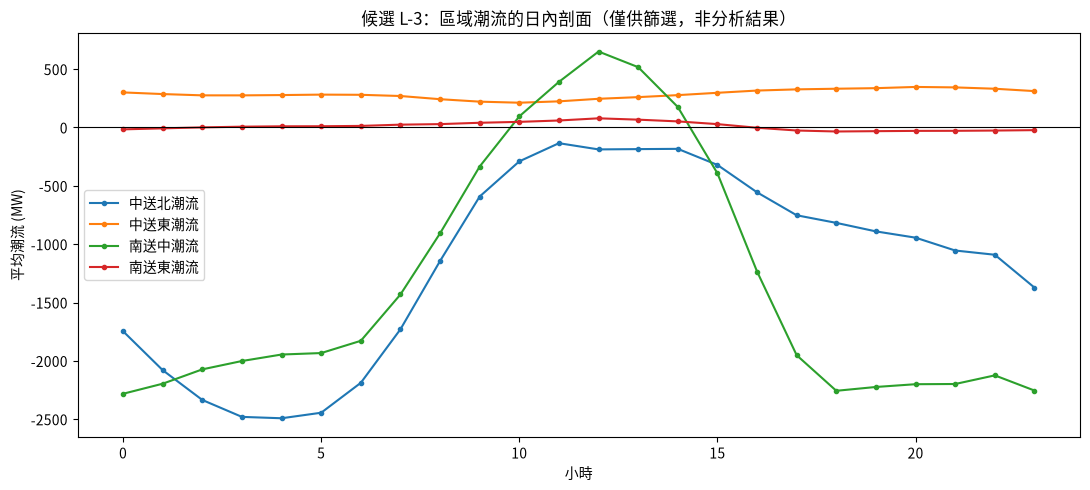

已輸出 explore_taipower_flow_hourly.png


In [10]:
hourly = (
    df.with_columns(pl.col("DATETIME").dt.hour().alias("時"))
    .group_by("UNIT_NAME", "時")
    .agg(pl.col("P").mean().alias("平均MW"))
    .sort("UNIT_NAME", "時")
)
fig, ax = plt.subplots(figsize=(11, 5))
for name in sorted(df["UNIT_NAME"].unique()):
    sub = hourly.filter(pl.col("UNIT_NAME") == name)
    ax.plot(sub["時"], sub["平均MW"], marker="o", markersize=3, label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("小時")
ax.set_ylabel("平均潮流 (MW)")
ax.set_title("候選 L-3：區域潮流的日內剖面（僅供篩選，非分析結果）")
ax.legend()
fig.tight_layout()
fig.savefig(FIGDIR / "explore_taipower_flow_hourly.png", dpi=120)
plt.show()
print("已輸出 explore_taipower_flow_hourly.png")

## 8. 各鏈路的時間序列

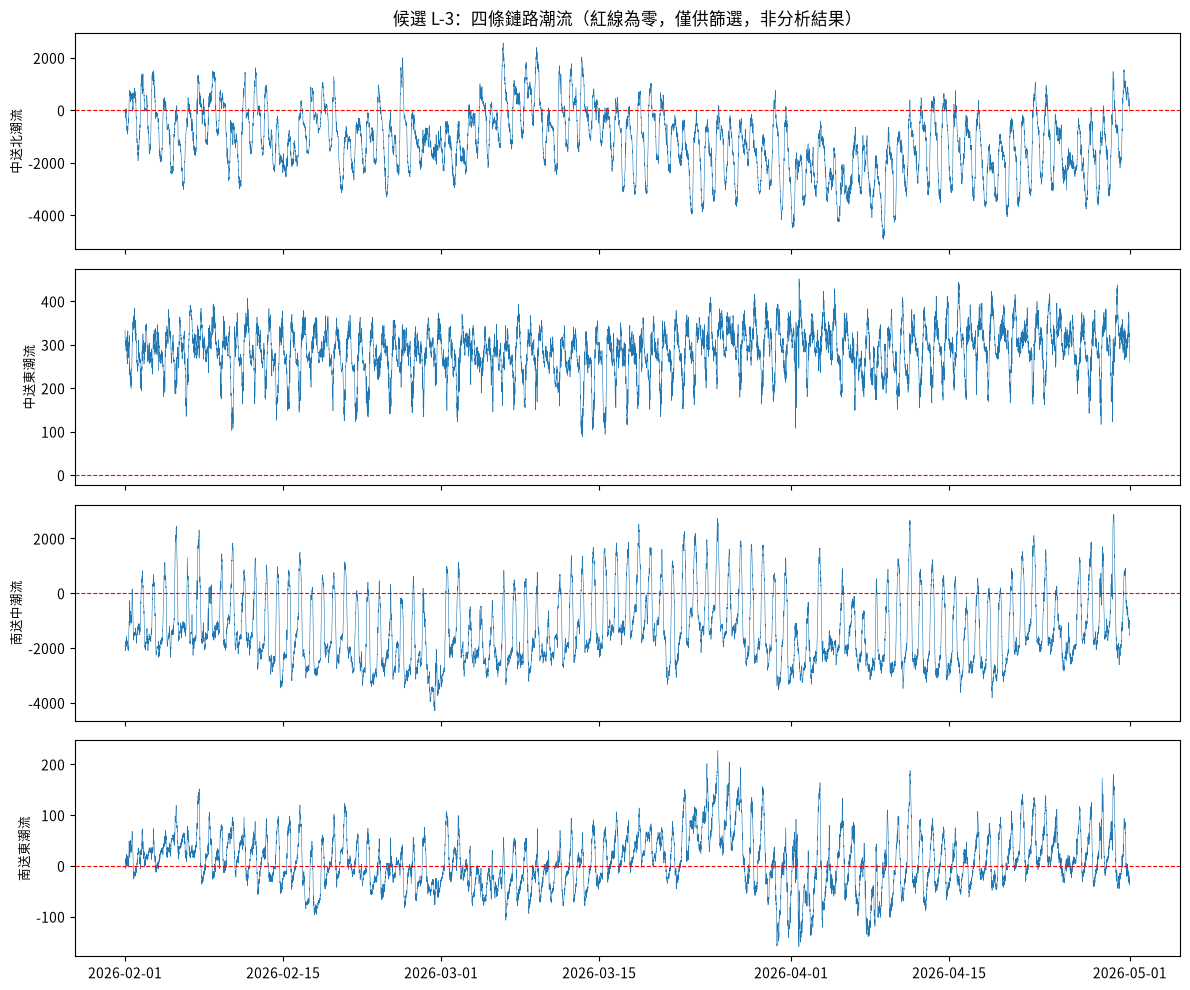

已輸出 explore_taipower_flow_series.png


In [11]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, name in zip(axes, sorted(df["UNIT_NAME"].unique())):
    sub = df.filter(pl.col("UNIT_NAME") == name).sort("DATETIME")
    ax.plot(sub["DATETIME"], sub["P"], linewidth=0.4)
    ax.axhline(0, color="red", linewidth=0.8, linestyle="--")
    ax.set_ylabel(name, fontsize=9)
axes[0].set_title("候選 L-3：四條鏈路潮流（紅線為零，僅供篩選，非分析結果）")
fig.tight_layout()
fig.savefig(FIGDIR / "explore_taipower_flow_series.png", dpi=120)
plt.show()
print("已輸出 explore_taipower_flow_series.png")

## 9. 單變數分布

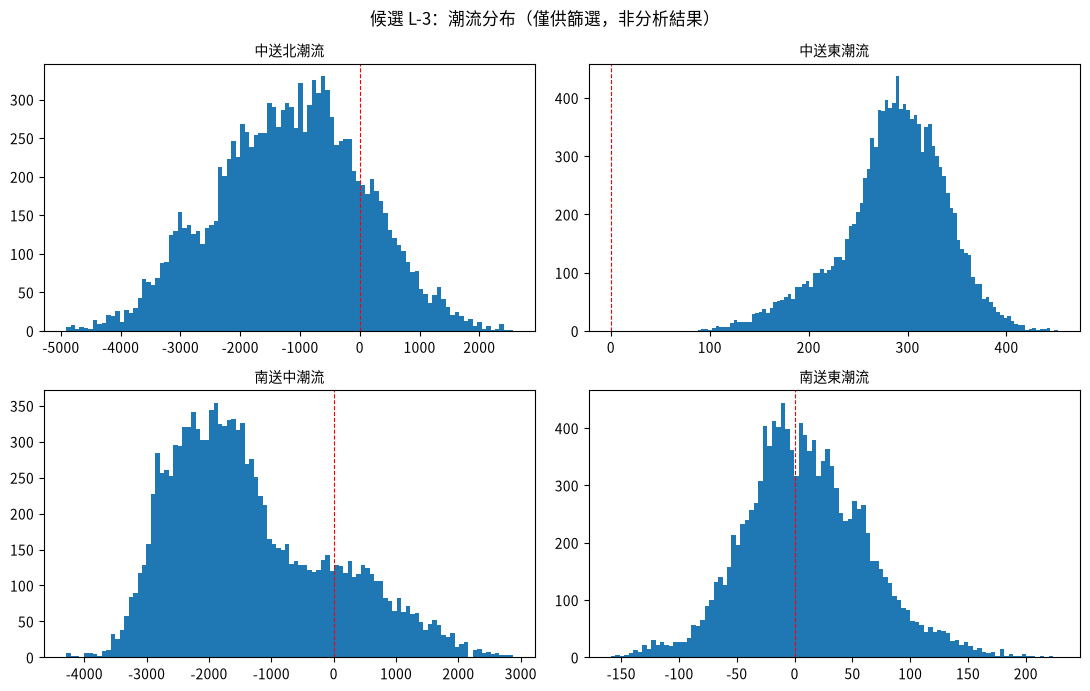

已輸出 explore_taipower_flow_hist.png


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axes.flat, sorted(df["UNIT_NAME"].unique())):
    s = df.filter(pl.col("UNIT_NAME") == name)["P"]
    ax.hist(s, bins=100)
    ax.axvline(0, color="red", linewidth=0.8, linestyle="--")
    ax.set_title(name, fontsize=10)
fig.suptitle("候選 L-3：潮流分布（僅供篩選，非分析結果）")
fig.tight_layout()
fig.savefig(FIGDIR / "explore_taipower_flow_hist.png", dpi=120)
plt.show()
print("已輸出 explore_taipower_flow_hist.png")

## 10. 鏈路間的相關（僅供篩選，非分析結果）

In [13]:
wide = df.pivot(on="UNIT_NAME", index="DATETIME", values="P").sort("DATETIME")
cols = [c for c in wide.columns if c != "DATETIME"]
print("四條鏈路的 Pearson 相關係數矩陣：")
corr = wide.select(cols).corr()
show(corr.with_columns(pl.Series("", cols)).select(["", *cols]))
print("\n僅供篩選，非分析結果。此矩陣用於確認鏈路間是否存在可建模的")
print("相依結構，不構成任何因果或迴歸推論。")

print("\n以上全部為篩選用檢視，非分析結果。")

四條鏈路的 Pearson 相關係數矩陣：
shape: (4, 5)
┌────────────┬────────────┬────────────┬────────────┬────────────┐
│            ┆ 中送東潮流 ┆ 中送北潮流 ┆ 南送中潮流 ┆ 南送東潮流 │
│ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        │
│ str        ┆ f64        ┆ f64        ┆ f64        ┆ f64        │
╞════════════╪════════════╪════════════╪════════════╪════════════╡
│ 中送東潮流 ┆ 1.0        ┆ -0.10799   ┆ -0.454097  ┆ -0.319486  │
│ 中送北潮流 ┆ -0.10799   ┆ 1.0        ┆ 0.439716   ┆ 0.136067   │
│ 南送中潮流 ┆ -0.454097  ┆ 0.439716   ┆ 1.0        ┆ 0.829215   │
│ 南送東潮流 ┆ -0.319486  ┆ 0.136067   ┆ 0.829215   ┆ 1.0        │
└────────────┴────────────┴────────────┴────────────┴────────────┘

僅供篩選，非分析結果。此矩陣用於確認鏈路間是否存在可建模的
相依結構，不構成任何因果或迴歸推論。

以上全部為篩選用檢視，非分析結果。
